---
title: "Coulaloglou and Tavlarides (1977): drop breakage and coalescence in a stirred vessel"
description: "The Coulaloglou-Tavlarides breakage and coalescence kernels in a steady population balance for a continuous-flow stirred vessel, asked whether the paper's N^(-6/5) scaling for the maximum stable drop size holds for d32 in its model, curves and data over its range of impeller speeds."
categories: [sec:J, struct:S11, tier:T0, data:tier6, phase:liquid-liquid]
date: 2026-11-24
---

# Coulaloglou and Tavlarides (1977): drop breakage and coalescence in a stirred vessel

**Catalog ID:** `J2.7` · **Structures:** `S11` (population balance) · **Tier:** T0

Coulaloglou and Tavlarides wrote down a breakage frequency, a daughter distribution, a
collision frequency and a film-drainage coalescence efficiency for drops in locally
isotropic turbulence, put them in a population balance for a continuous-flow stirred
vessel, and fitted four constants to drop sizes and coalescence frequencies measured in
a 12 l vessel. From the breakage frequency alone they derive, for the maximum stable drop
size where the exponential of eq. 14 dominates, $d_{max} \sim N^{\ast -6/5}$ (p. 1291), the
exponent of the classical $d_{32}/D \propto We^{-0.6}$; the paper does not claim it for
$d_{32}$. This page
rebuilds the model from the paper alone (it prints no physical properties, no feed and
no counting convention, and the page fixes each from the paper's own printed numbers),
solves the steady population balance, and asks whether $d_{32}$ in the model, its printed
curves and its data follows $N^{\ast -6/5}$ over the paper's own range of 190 to 310 rpm,
and if not, which process moves the exponent.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.10"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J2.7-coulaloglou-tavlarides-drop-size"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The population balance has no space coordinate, so the page uses no
# finite-volume operator; pymrm contributes newton (the steady solve), find_roots and
# observed_orders.
import contextlib
import io
import math
import re
from dataclasses import dataclass, field, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from scipy.sparse import csc_array
from scipy.sparse.linalg import splu
from pymrm import newton
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (PRINTED, Params, SteadyPBE, breakage_frequency, breakage_group,
                   collision_frequency, constant_kernel_number, contour_exponent, d_max,
                   diameter, efficiency, estimates, volume, x_from_efficiency)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In a stirred liquid-liquid dispersion the drop size distribution is set by breakage in
the turbulent eddies, by coalescence of colliding drops, and, in a continuous-flow
vessel, by the residence time. Coulaloglou and Tavlarides (1977) gave each process a
kernel from inertial-subrange turbulence and a population balance that couples them; the
kernels are still the default in many population-balance codes. Their breakage
frequency gives, for the largest drops, the scaling they quote on p. 1291: "$d_{max}
\sim N^{-6/5}$ which is in accordance with the data reported in the literature", derived
for $d_{max}$ where the exponential of eq. 14 dominates. The page asks whether the
scaling holds for $d_{32}$ in the paper's own model, curves and data. It does not
repeat the aggregation kinetics of `J2.6` (Smoluchowski, constant kernel) or the fixed
pivot discretisation of `J2.4`, which it uses and cites.

Not covered: spatial (two-region) models, Fig. 5 and the comparison with Ross and
with Mlynek and Resnick, the light-transmittance method, Fig. 1, and the measured
histograms of Fig. 2.

## The published model

Counts $NA(v)\,dv$ of drops of volume $v$ in the vessel obey (eqs. 2 to 4)

$$0 = \int_v^{v_{max}} \beta(v',v)\,\nu\, g(v')\, NA(v')\,dv' - g(v) NA(v)
  + \tfrac12\int_0^{v} \lambda h(v-v',v') NA(v-v') NA(v') dv'
  - NA(v)\int_0^{v_{max}-v} \lambda h(v,v') NA(v')\,dv' + n_0 A_0(v) - \frac{NA(v)}{\theta},$$

with the fitted kernels (eqs. 36, 37) and $\nu = 2$ daughters, normal in volume (eq. 15):

$$g(v) = C_1 v^{-2/9} D^{2/3} \frac{N^{\ast}}{1+\phi}
  \exp\!\Big[-\frac{C_2 \sigma (1+\phi)^2}{\rho_d v^{5/9} D^{4/3} N^{\ast 2}}\Big],\qquad
\beta(v',v) = \frac{2.4}{v'} \exp\!\Big[-4.5\frac{(2v-v')^2}{v'^2}\Big],$$

$$\lambda h(v,v') = C_3 (v^{2/3}+v'^{2/3})(v^{2/9}+v'^{2/9})^{1/2} D^{2/3}\frac{N^{\ast}}{1+\phi}
  \exp\!\Big[-C_4 \frac{\mu_c\rho_c}{\sigma^2}\frac{D^2 N^{\ast 3}}{(1+\phi)^3}
  \Big(\frac{v^{1/3}v'^{1/3}}{v^{1/3}+v'^{1/3}}\Big)^4\Big].$$

The paper compares the Sauter mean $d_{32} = \sum n_i d_i^3/\sum n_i d_i^2$ and the
volume coalescence frequency $\omega_v = (V_T\phi)^{-1}\iint v F\,dv'\,dv$ (eq. 34).

| symbol | code | meaning |
|---|---|---|
| $N^{\ast}$ | `n` | impeller speed, rev/s |
| $\phi$ | `phi` | dispersed-phase holdup |
| $S = \sigma/\rho_d$ | `s` | group in $g$, cm$^3$/s$^2$ |
| $X = \mu_c\rho_c/\sigma^2$ | `x` | group in $\lambda$, s$^3$/cm$^4$ |
| $y = C_2 S (1+\phi)^2/(v^{5/9} D^{4/3} N^{\ast 2})$ | `breakage_group` | exponent of $g$ |
| $y_k$ | `SteadyPBE` unknowns | drops per vessel at pivot $k$ |

Two printed forms are corrected (equations file of the build plan, misprints M1, M2):
eq. 25 prints the exponent 2 on $dd'/(d+d')$ where eqs. 23, 24 and 27 give 4 (with 2 the
right side has units s/cm$^2$), and eq. 32 prints the feed density without its minus
sign and with $2\sigma_0$ for $2\sigma_0^2$. The breakage contour $g$ = const gives, in
closed form (page derivation from eq. 36),

$$\frac{d\ln d}{d\ln N^{\ast}} = -\frac{3(1+2y)}{5y-2} \;\to\; -\frac65 \quad (y\to\infty),$$

so the paper's $-6/5$ for $d_{max}$ is the limit of breakage alone at large $y$.

## Parameters and assumptions

The constants are read from the printed-numbers file (strings, as printed). The paper
prints no interfacial tension, densities or viscosity, no feed distribution and no
tank diameter; the page works with the groups $S$ and $X$ and states each choice:

- **A1 counts per vessel.** The notation gives $N$ as the "total number of drops" and
  $h$, $F$ in s$^{-1}$, and eq. 34 divides by $V_T\phi$: $C_3$ carries the vessel volume.
  The reading per cm$^3$ ($C_3/V_T$) is computed beside it and is a break row.
- **A2 frequencies in s$^{-1}$**, as in the notation, $\theta$ = 10 min = 600 s. The axes
  of Figs. 1b and 4 print "mn$^{-1}$"; the reading in 1/min is a break row.
- **A3 $S$ calibrated** so that $d_{32}$ equals the printed calculated 0.250 mm of Fig. 2.
- **A4 $X$ from the printed 6 % efficiency** of p. 1295, with its one-digit rounding band.
- **A5 feed** Gaussian in volume, mean diameter 1 mm, standard deviation 0.1 of the mean
  volume; shown immaterial below.
- **A6 grid** pivots $x_k = x_1 2^{k/q}$, $x_1 = 10^{-8}$ cm$^3$ (27 µm), 17 doublings.
- **A7** the daughter distribution normalised on $[0, v']$ instead of the printed 2.4.

In [3]:
PN = load_data("coulaloglou-1977-printed-numbers.csv", page=PAGE, dtype=str, keep_default_na=False)
FIG3 = load_data("coulaloglou-1977-fig3.csv", page=PAGE, dtype={"phi": str})
FIG4 = load_data("coulaloglou-1977-fig4.csv", page=PAGE, dtype={"phi": str})
FIG2 = load_data("coulaloglou-1977-fig2-theory.csv", page=PAGE)
for f in ("coulaloglou-1977-printed-numbers.csv", "coulaloglou-1977-fig3.csv",
          "coulaloglou-1977-fig4.csv", "coulaloglou-1977-fig2-theory.csv"):
    print(cite_data(load_meta(f, page=PAGE)))


def num(pn, item):
    """A printed number as a float."""
    return float(pn.loc[pn["item"] == item, "printed"].iloc[0])


def half_unit(pn, item):
    """Half a unit in the last printed digit of an entry."""
    s = pn.loc[pn["item"] == item, "printed"].iloc[0].lower()
    mant, _, ex = s.partition("e")
    dec = len(mant.split(".")[1]) if "." in mant else 0
    return 0.5 * 10.0 ** (-dec) * 10.0 ** int(ex or 0)


SPEEDS = np.array([190.0, 220.0, 250.0, 280.0, 310.0])   # rpm, Figs. 3 and 4
PHIS = (0.05, 0.10, 0.15)
MARCH_FLOOR = 1e-6               # pivots below this fraction of the largest entry do not enter the stop rule
READ3, READ4 = 0.0012, 0.007    # sidecar reading errors: mm (Fig. 3), relative (Fig. 4)


@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    pn: object = field(default_factory=lambda: PN)
    over: tuple = ()          # Params overrides ((field, value), ...)
    q: int = 8                # production grid
    unit: float = 1.0         # model omega_v (1/s) times unit before a comparison with the paper
    est: tuple = ()           # reading of the pp. 1295-1296 estimates
    lam6: float = None        # efficiency of p. 1295; None: the printed 6 %
    d0: float = 0.1           # feed mean diameter, cm
    x1: float = 1e-8          # smallest pivot, cm3
    octaves: int = 17         # volume doublings of the grid
    fd_h: float = 1e-4        # step of the R2 finite difference in ln N*
    comp_c3: float = 1.0      # C3 factor of the round-off companion solve (V3)
    c1_qdefect: float = 0.0   # C1 times (1 + c1_qdefect/q^3) on the V3 ladder (a grid-dependent defect)
    fig3: object = field(default_factory=lambda: FIG3)
    fig4: object = field(default_factory=lambda: FIG4)
    fig2: object = field(default_factory=lambda: FIG2)
    ladder: tuple = (4, 8, 16, 32, 64)
    v2_feedfac: float = 1.0   # feed factor of the balance the V2 newton route solves
    v2_xfac: float = 1e6      # X factor of the lambda -> 0 limit
    v2_c3fac: float = 1e-10   # C3 factor of the C3 -> 0 continuity check
    bdf_span: float = 60.0    # BDF horizon in residence times
    march_inc: float = 1e-3   # the paper's stop rule of the marching iteration (p. 1293): relative change per increment


def params(cfg):
    """Params from the printed strings, then the row's overrides."""
    pn = cfg.pn
    p = Params(C1=num(pn, "C1"), C2=num(pn, "C2"), C3=num(pn, "C3"), C4=num(pn, "C4"),
               D=num(pn, "D_cm"), VT=num(pn, "V_T_l") * 1000.0, theta=num(pn, "theta_min") * 60.0)
    return replace(p, **dict(cfg.over))


C0 = Cfg()
P0 = params(C0)
say("Printed constants: $C_1$ = <<C1:g>>, $C_2$ = <<C2:g>>, $C_3$ = <<C3:g>> cm$^{-3}$, "
    "$C_4$ = <<C4:g>> cm$^{-2}$; $D$ = <<D:g>> cm, $V_T$ = <<VT:g>> cm$^3$, "
    "$\\theta$ = <<th:g>> s.", C1=P0.C1, C2=P0.C2, C3=P0.C3, C4=P0.C4, D=P0.D, VT=P0.VT, th=P0.theta)

Coulaloglou, C. A.; Tavlarides, L. L. (1977) — Chemical Engineering Science 32, 1289-1297 — doi:10.1016/0009-2509(77)85023-9 — table
Coulaloglou, C. A.; Tavlarides, L. L. (1977) — Chemical Engineering Science 32, 1289-1297 — doi:10.1016/0009-2509(77)85023-9 — digitised from Fig. 3, journal page 1294
Coulaloglou, C. A.; Tavlarides, L. L. (1977) — Chemical Engineering Science 32, 1289-1297 — doi:10.1016/0009-2509(77)85023-9 — digitised from Fig. 4, journal page 1295
Coulaloglou, C. A.; Tavlarides, L. L. (1977) — Chemical Engineering Science 32, 1289-1297 — doi:10.1016/0009-2509(77)85023-9 — digitised from Fig. 2, journal page 1294


Printed constants: $C_1$ = 0.4, $C_2$ = 0.08, $C_3$ = 2.8e-06 cm$^{-3}$, $C_4$ = 1.83e+09 cm$^{-2}$; $D$ = 10 cm, $V_T$ = 12000 cm$^3$, $\theta$ = 600 s.

## The data

Four files, each with a `.meta.yaml` sidecar: the printed numbers (constants, captions,
the vessel data and the estimates of pp. 1295 and 1296, kept as strings); the symbols
and model lines of Fig. 3 ($d_{32}$ against $N^{\ast}$, reading error ±0.0012 mm); those of
Fig. 4 ($\omega_v$ against $N^{\ast}$, log axis printed in mn$^{-1}$, reading error ±0.7 %);
and the theory curve of Fig. 2 to 0.495 mm. No dataset is borrowed from another page.
Two reading notes from the sidecars: the top frame line of Fig. 3 is labelled "0 50" but
sits one tick spacing above 0.48 on the ladder, and the tick ladder is used; one Fig. 4
symbol at 220 rpm has an undecidable shape and is kept as `unassigned`, outside every
series. The paper fitted $C_1$ to $C_4$ to these same Figs. 3 and 4 data at
$\phi$ = 0.05 (p. 1294), so agreement with them is not a validation of the model.

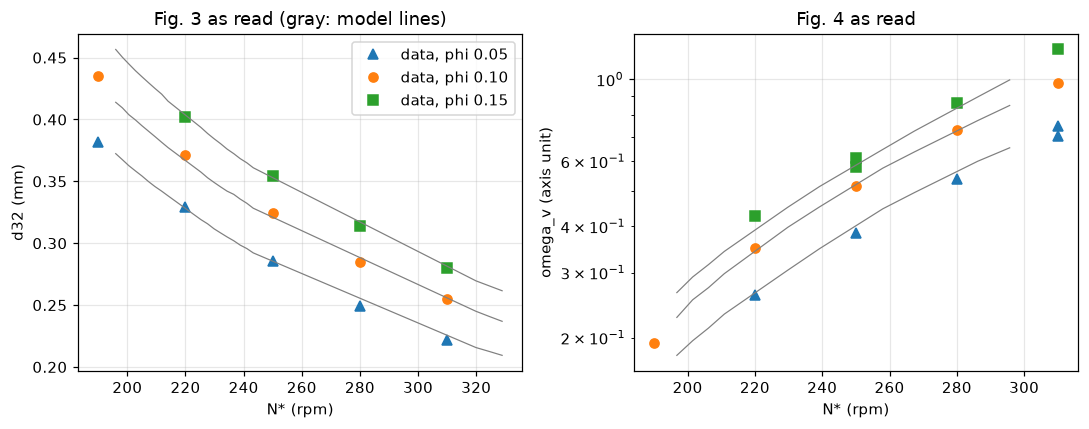

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for phi, mk in zip(("0.05", "0.10", "0.15"), ("^", "o", "s")):
    s3 = FIG3[(FIG3.phi == phi) & (FIG3.kind == "symbol")]
    l3 = FIG3[(FIG3.phi == phi) & (FIG3.kind == "line")]
    ax[0].plot(s3.N_nominal_rpm, s3.d32_mm, mk, label=f"data, phi {phi}")
    ax[0].plot(l3.N_read_rpm, l3.d32_mm, "-", lw=0.8, color="gray")
    s4 = FIG4[(FIG4.phi == phi) & (FIG4.kind == "symbol")]
    l4 = FIG4[(FIG4.phi == phi) & (FIG4.kind == "line")]
    ax[1].semilogy(s4.N_nominal_rpm, s4.omega_axis_per_min, mk)
    ax[1].semilogy(l4.N_read_rpm, l4.omega_axis_per_min, "-", lw=0.8, color="gray")
ax[0].set(xlabel="N* (rpm)", ylabel="d32 (mm)", title="Fig. 3 as read (gray: model lines)")
ax[1].set(xlabel="N* (rpm)", ylabel="omega_v (axis unit)", title="Fig. 4 as read")
ax[0].legend()
plt.tight_layout()
plt.show()

## PyMRM implementation

`model.SteadyPBE` discretises the balance on fixed pivots (Kumar and Ramkrishna; the
subject of `J2.4`): breakage daughters and coalescence products are shared between the
two neighbouring pivots so that volume is conserved exactly per event and number per
coalescence. The breakage matrix uses the closed-form integrals of the Gaussian daughter
distribution. The residual and its analytic dense Jacobian go to `pymrm.newton` (bounds
at zero, scaled by the largest unknown, stagnation stop), started from the exact
breakage-only state, which a back substitution from the largest pivot gives (the
paper's marching, p. 1293). Thresholds and calibrations are roots by
`pymrm.checks.find_roots`; grid orders come from `pymrm.checks.observed_orders`.

### Check values

Before any claim, the page's functions are checked against values computed by a
second route (numpy and scipy, written apart from this page) at a test condition T:
310 rpm, $\phi$ = 0.10, $S$ = 48 cm$^3$/s$^2$, $q$ = 8.

In [5]:
NT, PHIT, ST = 31 / 6, 0.10, 48.0
X6 = x_from_efficiency(p=P0)


def pbe(q, n, phi, s, x, p=P0, **kw):
    """Model and steady state."""
    m = SteadyPBE(q, n, phi, s, x, p=p, **kw)
    y, info = m.solve()
    return m, y, info


def check_values():
    cv = {}
    der = {"CI": P0.C1 / 1.15, "CII": P0.C2 * 1.15**2, "CIII": P0.C3 / 1.15, "CIV": P0.C4 / 1.15**3}
    for k in der:
        cv[f"fig1_{k}_from_eq36_37"] = der[k]
        item = {"CI": "fig1_CI", "CII": "fig1_CII", "CIII": "fig1_CIII", "CIV": "fig1_CIV"}[k]
        cv[f"fig1_{k}_halfunits_off"] = abs(num(PN, item) - der[k]) / half_unit(PN, item)
    m8 = SteadyPBE(8, NT, PHIT, ST, X6)
    zk = (m8.x[5] / 6) * math.sqrt(2 * math.pi) * math.erf(3 / math.sqrt(2))
    cv["beta_exact_prefactor"] = m8.x[5] * math.erf(3 / math.sqrt(2)) / zk   # 6/sqrt(2 pi)
    cv["beta_fraction_in_0_vp"] = math.erf(3 / math.sqrt(2))
    cv["beta_printed_number_on_0_vp"] = 2.4 / m8.x[5] * zk
    for h, k in ((1000, "h1000"), (500, "h500")):
        cv[f"C4_est_{k}_tbar_d_over_u"] = estimates()[f"C4_{k}"]
        cv[f"C4_est_{k}_eq26_unity"] = estimates(contact="unity")[f"C4_{k}"]
    e, e2 = estimates(), estimates(c2="1/2")
    cv["C2_est_over_c1"], cv["C2_est_over_c1_c2_half"] = e["C2_over_c1"], e2["C2_over_c1"]
    cv["C1_est_times_c5"] = e["C1_c5"]
    cv["c1_implied"], cv["c5_implied"] = P0.C2 / e["C2_over_c1"], e["C1_c5"] / P0.C1
    cv["C3_est_per_vessel_with_rotta"] = estimates(rotta_in_c3=True)["C3"]
    cv["C3_est_per_vessel_no_rotta"] = e["C3"]
    cv["C3_est_per_volume_with_rotta"] = estimates(rotta_in_c3=True)["C3"] * P0.VT
    cv["C3_est_no_rotta_over_fitted"] = e["C3"] / P0.C3
    cv["X_from_6pct"], cv["X_from_6p5pct"], cv["X_from_5p5pct"] = X6, x_from_efficiency(0.065), x_from_efficiency(0.055)
    cv["sigma_if_mu_rho_0p01"] = math.sqrt(0.01 / X6)
    cv["X_6pct_without_phi_damping"] = x_from_efficiency(p=replace(P0, damp=0.0))
    for dmm in (0.25, 0.5):
        v = float(volume(dmm / 10))
        cv[f"T_g_d{dmm}mm"] = float(breakage_frequency(v, NT, PHIT, ST))
        cv[f"T_y_d{dmm}mm"] = float(breakage_group(v, NT, PHIT, ST))
    v = float(volume(0.025))
    cv["T_h_pair_d0.25mm"] = float(collision_frequency(v, v, NT, PHIT))
    cv["T_lambda_d0.25mm"] = float(efficiency(v, v, NT, PHIT, X6))
    dm = d_max(NT, PHIT, ST)
    ystar = float(breakage_group(volume(dm), NT, PHIT, ST))
    cv["T_dmax_g_theta_1_cm"], cv["T_y_at_dmax"] = dm, ystar
    cv["T_contour_exponent_closed"] = contour_exponent(ystar)
    cv["holdup_asymptote_ratio_015_005"] = (1.15 / 1.05) ** 1.2
    cv["cstr_const_kernel_N"] = constant_kernel_number(1e-9, 1e6, P0.theta)
    m, y, _ = pbe(8, NT, PHIT, ST, X6)
    st = m.stats(y)
    cv["T_q8_number_deficit_per_daughter"], cv["T_q8_number_deficit_per_fed_drop"] = m.number_deficit(y)
    cv["T_q8_d32_cm"], cv["T_q8_omega_v_per_s"] = st["d32"], st["omega_v"]
    cv["T_q8_omega_n_per_s"], cv["T_q8_Ndrops_vessel"] = st["omega_n"], st["N"]
    cv["T_q8_d32_breakage_only_cm"] = m.stats(m.breakage_only())["d32"]
    mv, yv, _ = pbe(8, NT, PHIT, ST, X6, p=replace(P0, per_volume=True))
    cv["T_q8_d32_per_volume_reading_cm"] = mv.stats(yv)["d32"]
    cv["T_q8_omega_v_per_volume_reading_per_s"] = mv.stats(yv)["omega_v"]
    lad = {q: pbe(q, NT, PHIT, ST, X6) for q in (8, 16, 32, 64)}
    for key in ("d32", "omega_v"):
        o = observed_orders(lambda q: lad[q][0].stats(lad[q][1])[key], (8, 16, 32, 64))
        cv[f"T_order_{key}_q8_16_32"], cv[f"T_order_{key}_q16_32_64"] = o["orders"]
        cv[f"T_extrapolated_{key}"] = o["extrapolated"]
    def d32_minus(s):
        m_, y_, _ = pbe(8, NT, PHIT, s, X6)
        return m_.stats(y_)["d32"] - 0.025
    r = find_roots(d32_minus, 30.0, 80.0, n_scan=8, xtol=1e-11)["roots"]
    assert len(r) == 1
    mc, yc, _ = pbe(8, NT, PHIT, r[0], X6)
    cv["T_q8_S_calibrated"] = r[0]
    cv["T_q8_omega_v_at_S_cal_per_s"] = mc.stats(yc)["omega_v"]
    cv["T_q8_omega_v_at_S_cal_per_min"] = mc.stats(yc)["omega_v"] * 60
    full, brk = [], []
    for rpm in SPEEDS:
        mm, yy, _ = pbe(8, rpm / 60, PHIT, ST, X6)
        full.append(mm.stats(yy)["d32"])
        brk.append(mm.stats(mm.breakage_only())["d32"])
    cv["T_q8_slope_full"] = np.polyfit(np.log(SPEEDS), np.log(full), 1)[0]
    cv["T_q8_slope_breakage_only"] = np.polyfit(np.log(SPEEDS), np.log(brk), 1)[0]
    return cv


CV = check_values()
with contextlib.redirect_stdout(io.StringIO()):     # its worst deviation is round-off and varies by kernel
    DEV = assert_check_values(CV, page=PAGE)
print(f"check values: {len(DEV)} of {len(CV)} agree, every one inside its rtol (worst below 1e-8)")

check values: 60 of 60 agree, every one inside its rtol (worst below 1e-8)


### The study

`study(cfg, parts)` computes every number the page reports; the break table reruns it
with one defect at a time, and only the parts the defect reaches.

In [6]:
def calibrate(cfg, p, x, q, lo=10.0, hi=400.0, n_scan=48):
    """Every S on [lo, hi] with d32 = the printed calc d32 of Fig. 2 (find_roots)."""
    n, phi = num(cfg.pn, "fig2_N_rpm") / 60, num(cfg.pn, "fig2_phi")
    target = num(cfg.pn, "fig2_d32_calc_mm") / 10

    def f(s):
        m, y, _ = pbe(q, n, phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
        return m.stats(y)["d32"] / target - 1
    return find_roots(f, lo, hi, n_scan=n_scan, log=True, xtol=1e-10)["roots"]


def rel(a, b):
    """Relative change of a against b (absolute when b is zero)."""
    return abs(a / b - 1) if b else abs(a - b)


def part_closed(cfg, p, M):
    """R1: the Fig. 1 caption constants and the paper's estimates; X from the 6 %."""
    pn, phi = cfg.pn, num(cfg.pn, "fig1_phi")
    der = {"CI": p.C1 / (1 + phi) ** p.damp, "CII": p.C2 * (1 + phi) ** (2 * p.damp),
           "CIII": p.C3 / (1 + phi) ** p.damp, "CIV": p.C4 / (1 + phi) ** (3 * p.damp)}
    hu = {k: abs(num(pn, f"fig1_{k}") - der[k]) / half_unit(pn, f"fig1_{k}") for k in der}
    for k in der:
        M[f"r1_fig1_{k}_half_units"] = hu[k]
    M["r1_fig1_n_follow"] = int(sum(h <= 1 for h in hu.values()))
    M["r1_fig1_n_follow__margin"] = min(abs(h - 1) for h in hu.values())
    e = estimates(**dict(cfg.est))
    M["r1_C4_est_h1000"], M["r1_C4_est_h500"] = e["C4_h1000"], e["C4_h500"]
    h4 = [abs(e["C4_h1000"] - num(pn, "C4_est_h1000")) / half_unit(pn, "C4_est_h1000"),
          abs(e["C4_h500"] - num(pn, "C4_est_h500")) / half_unit(pn, "C4_est_h500")]
    M["r1_C4_est_n_reproduced"] = int(sum(h <= 1 for h in h4))
    M["r1_C4_est_n_reproduced__margin"] = min(abs(h - 1) for h in h4)
    br = min(math.log(p.C4 / e["C4_h1000"]), math.log(e["C4_h500"] / p.C4))
    M["r1_C4_bracket_holds"], M["r1_C4_bracket_holds__margin"] = bool(br > 0), abs(br)
    M["r1_C3_est"] = e["C3"]
    M["r1_C3_est_half_units"] = abs(e["C3"] - num(pn, "C3_est")) / half_unit(pn, "C3_est")
    if p.C3 > 0:
        M["r1_C3_est_over_fitted"] = e["C3"] / p.C3
    M["r1_C2_est_half_units"] = abs(e["C2_over_c1"] - num(pn, "C2_est_coef")) / half_unit(pn, "C2_est_coef")
    M["r1_C1_est_half_units"] = abs(e["C1_c5"] - num(pn, "C1_est_coef")) / half_unit(pn, "C1_est_coef")
    M["r1_c1_implied"], M["r1_c5_implied"] = p.C2 / e["C2_over_c1"], e["C1_c5"] / p.C1
    lam = num(pn, "lambda_6pct") / 100 if cfg.lam6 is None else cfg.lam6
    args = dict(v=num(pn, "v6_a_cm3"), w=num(pn, "v6_b_cm3"), n=num(pn, "N_6pct_rps"),
                phi=num(pn, "phi_6pct"), p=p)
    hl = half_unit(pn, "lambda_6pct") / 100
    M["r1_X"] = x_from_efficiency(lam, **args)
    M["_X_band"] = (x_from_efficiency(lam + hl, **args), x_from_efficiency(lam - hl, **args))
    M["r1_sigma_if_mu_rho_001"] = math.sqrt(0.01 / M["r1_X"])


def part_cal(cfg, p, M):
    """R3: S calibrated to the printed calc d32; omega_v against the printed calc."""
    x, q = M["r1_X"], cfg.q
    n, phi = num(cfg.pn, "fig2_N_rpm") / 60, num(cfg.pn, "fig2_phi")
    roots = calibrate(cfg, p, x, q)
    M["r3_n_roots"] = len(roots)
    if len(roots) != 1:
        return
    s = M["_S"] = M["r3_S"] = roots[0]
    m, y, info = pbe(q, n, phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
    st = m.stats(y)
    M["_T"] = (m, y)
    om, pr = st["omega_v"] * cfg.unit, num(cfg.pn, "fig2_omega_v_calc")
    M["r3_omega_v"], M["r3_omega_v_ratio"] = st["omega_v"], om / pr
    M["r3_omega_v_half_units"] = abs(om - pr) / half_unit(cfg.pn, "fig2_omega_v_calc")
    M["r3_omega_v_ratio_if_per_min"] = om * 60 / pr
    M["r3_omega_n"], M["r3_N"] = st["omega_n"], st["N"]
    M["_r3_newton_nit"], M["_r3_newton_residual"] = info["newton"].nit, info["residual"]
    if info["residual"] > 1e-10:
        raise RuntimeError(f"steady residual {info['residual']:.1e}")
    band = []
    for xb in M["_X_band"]:
        rb = calibrate(cfg, p, xb, q, lo=s * 0.8, hi=s * 1.25, n_scan=4)
        mb, yb, _ = pbe(q, n, phi, rb[0], xb, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
        band.append(mb.stats(yb)["omega_v"] * cfg.unit / pr)
    M["r3_omega_v_band_lo"], M["r3_omega_v_band_hi"] = min(band), max(band)
    inside = min(1 - min(band), max(band) - 1)
    M["r3_printed_in_band"], M["r3_printed_in_band__margin"] = bool(inside > 0), abs(inside)
    d32b = m.stats(m.breakage_only())["d32"]
    M["r3_d32_brk_mm"], M["r3_coal_factor"] = d32b * 10, st["d32"] / d32b
    pv = replace(p, per_volume=not p.per_volume)
    rv = calibrate(cfg, pv, x, q)
    M["r3_pv_n_roots"] = len(rv)
    if len(rv) == 1:
        mv, yv, _ = pbe(q, n, phi, rv[0], x, p=pv, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
        M["r3_pv_S"], M["r3_pv_omega_v"] = rv[0], mv.stats(yv)["omega_v"]
        M["r3_pv_ratio_if_per_min"] = mv.stats(yv)["omega_v"] * 60 / pr
    feed = []
    for kw in ({"d0": 0.06}, {"d0": 0.2}, {"rel0": 0.3}):
        kw = {"d0": cfg.d0, **kw} if "rel0" in kw else kw
        mf, yf, _ = pbe(q, n, phi, s, x, p=p, x1=cfg.x1, octaves=cfg.octaves, **kw)
        feed.append(abs(mf.stats(yf)["d32"] / st["d32"] - 1))
    M["r3_feed_max_change"] = max(feed)
    dom = []
    for kw in ({"x1": cfg.x1 / 2, "octaves": cfg.octaves + 1}, {"x1": cfg.x1, "octaves": cfg.octaves + 1}):
        md, yd, _ = pbe(q, n, phi, s, x, p=p, d0=cfg.d0, **kw)
        dom += [rel(md.stats(yd)[k], st[k]) for k in ("d32", "omega_v")]
    M["r3_domain_max_change"] = max(dom)


def part_closed_r2(cfg, p, M):
    """R2: d_max of breakage alone (g theta = 1) at the 15 conditions, at the calibrated S."""
    s, out = M["_S"], {}
    for phi in PHIS:
        dm = np.array([d_max(r / 60, phi, s, p) for r in SPEEDS])
        ys = np.array([float(breakage_group(volume(d), r / 60, phi, s, p)) for d, r in zip(dm, SPEEDS)])
        out[phi] = (dm, ys)
        M[f"r2_slope_{phi:.2f}"] = np.polyfit(np.log(SPEEDS), np.log(dm), 1)[0]
    ys = np.concatenate([out[f][1] for f in PHIS])
    ms = contour_exponent(ys)
    M["r2_y_min"], M["r2_y_max"] = ys.min(), ys.max()
    M["r2_m_min"], M["r2_m_max"] = ms.min(), ms.max()
    yT = out[0.10][1][-1]
    M["r2_y_T"], M["r2_m_T"] = yT, contour_exponent(yT)
    h, nT = cfg.fd_h, SPEEDS[-1] / 60
    fd = (math.log(d_max(nT * math.exp(h), 0.10, s, p)) - math.log(d_max(nT * math.exp(-h), 0.10, s, p))) / (2 * h)
    M["r2_fd_gap"] = abs(fd / M["r2_m_T"] - 1)
    M["r2_holdup_asymptote"] = ((1 + 0.15) / (1 + 0.05)) ** (1.2 * p.damp)
    M["r2_holdup_dmax"] = out[0.15][0][-1] / out[0.05][0][-1]
    M["_r2"] = out


def line_at(df, phi, col, speeds):
    """Model line of a figure at given speeds: quadratic in ln-ln through the line reads."""
    l = df[(df.phi == phi) & (df.kind == "line")]
    c = np.polyfit(np.log(l.N_read_rpm.astype(float)), np.log(l[col].astype(float)), 2)
    return np.exp(np.polyval(c, np.log(speeds)))


def regress(xv, yv):
    """Slope, its standard error and dof of ln y on ln x."""
    r = stats.linregress(np.log(xv), np.log(yv))
    return r.slope, r.stderr, len(xv) - 2


def read_se(A, d32):
    """Standard error of the first coefficient of ln d32 on the design matrix A (ln N first)
    when every read d32 carries the figure-reading error READ3 (mm) as one standard
    deviation, propagated through the least-squares weights."""
    A = np.asarray(A, dtype=float)
    w = (np.linalg.inv(A.T @ A) @ A.T)[0]
    return float(np.sqrt(np.sum((w * READ3 / d32) ** 2)))


def part_sweep(cfg, p, M):
    """R4, R5: the 15 conditions at q and 2q (extrapolated), the data and the lines."""
    s, x = M["_S"], M["r1_X"]
    res = {}
    for phi in PHIS:
        vals = {}
        for q in (cfg.q, 2 * cfg.q):
            rows = []
            for r in SPEEDS:
                m, y, _ = pbe(q, r / 60, phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
                st = m.stats(y)
                rows.append((st["d32"], st["omega_v"], m.stats(m.breakage_only())["d32"]))
                if q == cfg.q:
                    M.setdefault("_models", []).append((m, y))
            vals[q] = np.array(rows)
        res[phi] = vals[2 * cfg.q] + (vals[2 * cfg.q] - vals[cfg.q]) / 3   # order 2 (V3)
        mf = regress(SPEEDS, res[phi][:, 0])[0]
        mb = regress(SPEEDS, res[phi][:, 2])[0]
        M[f"r5_m_full_{phi:.2f}"], M[f"r5_m_brk_{phi:.2f}"] = mf, mb
        M[f"r5_shift_res_{phi:.2f}"], M[f"r5_shift_coal_{phi:.2f}"] = mb + 1.2, mf - mb   # breakage-only slope less -6/5; full less breakage-only
        M[f"_grid_{phi}"] = abs(mf - regress(SPEEDS, vals[2 * cfg.q][:, 0])[0])
        d = cfg.fig3[(cfg.fig3.phi == f"{phi:.2f}") & (cfg.fig3.kind == "symbol")]
        sl, se_res, dof = regress(d.N_nominal_rpm.astype(float), d.d32_mm.astype(float))
        lnN = np.log(d.N_nominal_rpm.astype(float).to_numpy())
        se_rd = read_se(np.column_stack([lnN, np.ones_like(lnN)]), d.d32_mm.astype(float).to_numpy())
        se = max(se_res, se_rd)    # the larger of the regression and the reading-error term
        M[f"_r5_se_res_{phi:.2f}"], M[f"_r5_se_read_{phi:.2f}"], M[f"_r5_dof_{phi:.2f}"] = se_res, se_rd, dof
        M[f"r5_data_m_{phi:.2f}"], M[f"r5_data_se_{phi:.2f}"] = sl, se
        M[f"r5_data_t_{phi:.2f}"] = (sl + 1.2) / se
        M[f"r5_line_m_{phi:.2f}"] = regress(SPEEDS, line_at(cfg.fig3, f"{phi:.2f}", "d32_mm", SPEEDS))[0]
    M["r5_slope_grid_err"] = max(M[f"_grid_{phi}"] for phi in PHIS)
    ts = [M[f"r5_data_t_{phi:.2f}"] for phi in PHIS]
    tc = [float(stats.t.ppf(0.975, M[f"_r5_dof_{phi:.2f}"])) for phi in PHIS]   # two-sided 95 %
    M["_r5_tcrit"] = tc
    M["r5_n_data_excl"] = int(sum(abs(t) > c for t, c in zip(ts, tc)))
    M["r5_n_data_excl__margin"] = min(abs(abs(t) - c) / c for t, c in zip(ts, tc))
    # pooled: common slope, one intercept per holdup (rule 35)
    d = cfg.fig3[(cfg.fig3.kind == "symbol") & cfg.fig3.phi.isin(["0.05", "0.10", "0.15"])]
    X = np.column_stack([np.log(d.N_nominal_rpm.astype(float))]
                        + [(d.phi == f).astype(float) for f in ("0.05", "0.10", "0.15")])
    yv = np.log(d.d32_mm.astype(float).to_numpy())
    beta, rss, *_ = np.linalg.lstsq(X, yv, rcond=None)
    dof = len(yv) - X.shape[1]
    se_res = math.sqrt(float(rss[0]) / dof * np.linalg.inv(X.T @ X)[0, 0])
    se_rd = read_se(X, d.d32_mm.astype(float).to_numpy())
    se = max(se_res, se_rd)
    M["_r5_pooled_se_res"], M["_r5_pooled_se_read"] = se_res, se_rd
    M["r5_pooled_m"], M["r5_pooled_se"], M["r5_pooled_dof"] = beta[0], se, dof
    M["r5_pooled_t"] = (beta[0] + 1.2) / se
    # holdup ratio at 310 rpm
    M["r5_holdup_full"] = res[0.15][-1, 0] / res[0.05][-1, 0]
    M["r5_holdup_brk"] = res[0.15][-1, 2] / res[0.05][-1, 2]
    s3 = cfg.fig3[cfg.fig3.kind == "symbol"]
    at = lambda f: float(s3[(s3.phi == f) & (s3.N_nominal_rpm.astype(float) == 310)].d32_mm.iloc[0])
    M["r5_holdup_data"] = at("0.15") / at("0.05")
    M["r5_holdup_line"] = (line_at(cfg.fig3, "0.15", "d32_mm", SPEEDS[-1:])[0]
                           / line_at(cfg.fig3, "0.05", "d32_mm", SPEEDS[-1:])[0])
    # R4a: model against the printed model lines, no further fitting
    dev3 = np.concatenate([res[phi][:, 0] * 10 - line_at(cfg.fig3, f"{phi:.2f}", "d32_mm", SPEEDS) for phi in PHIS])
    M["r4_fig3_n_inside"] = int(np.sum(np.abs(dev3) <= READ3))
    M["r4_fig3_n_inside__margin"] = float(np.min(np.abs(np.abs(dev3) - READ3)) / READ3)
    M["r4_fig3_max_dev_mm"] = float(np.max(np.abs(dev3)))
    M["r4_fig3_n_points"] = len(dev3)
    mid = SPEEDS[1:4]
    rat = np.concatenate([res[phi][1:4, 1] * cfg.unit / line_at(cfg.fig4, f"{phi:.2f}", "omega_axis_per_min", mid)
                          for phi in PHIS])
    M["r4_fig4_n_inside"] = int(np.sum(np.abs(rat - 1) <= READ4))
    M["r4_fig4_n_inside__margin"] = float(np.min(np.abs(np.abs(rat - 1) - READ4)) / READ4)
    M["r4_fig4_max_rel_dev"] = float(np.max(np.abs(rat - 1)))
    M["r4_fig4_mean_ratio"] = float(np.mean(rat))
    M["r4_fig4_n_points"] = len(rat)
    M["_res"] = res


def local_m(cfg, p, s, x, n_rpm, phi, h=0.01):
    """d ln d32/d ln N* by central differences, q and 2q extrapolated."""
    out = []
    for q in (cfg.q, 2 * cfg.q):
        d = [pbe(q, n_rpm / 60 * math.exp(e), phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves) for e in (h, -h)]
        out.append((math.log(d[0][0].stats(d[0][1])["d32"]) - math.log(d[1][0].stats(d[1][1])["d32"])) / (2 * h))
    return out[1] + (out[1] - out[0]) / 3


def part_local(cfg, p, M):
    """R5: local exponents at the ends of the range, and the N* where m = -6/5."""
    s, x = M["_S"], M["r1_X"]
    loc = [local_m(cfg, p, s, x, r, phi) for phi in PHIS for r in (190.0, 310.0)]
    M["r5_mloc_min"], M["r5_mloc_max"] = min(loc), max(loc)
    r = find_roots(lambda n: local_m(cfg, p, s, x, n, 0.10) + 1.2, 100.0, 600.0,
                   n_scan=16, xtol=1e-6)
    M["r5_n_roots_m_65"] = len(r["roots"])
    M["_mroot"] = r["roots"]


def part_fig2(cfg, p, M):
    """R4b: the model volume density at the Fig. 2 point against the printed theory curve."""
    s, x = M["_S"], M["r1_X"]
    n, phi = num(cfg.pn, "fig2_N_rpm") / 60, num(cfg.pn, "fig2_phi")
    m, y, _ = pbe(32, n, phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
    dmm = diameter(m.x) * 10
    edges = diameter(m.x[0] * 2.0 ** ((np.arange(m.n + 1) - 0.5) / 32)) * 10
    wv = m.x * y / np.sum(m.x * y)
    A = wv / np.diff(edges)
    sp = CubicSpline(dmm, A)
    r = find_roots(lambda d: float(sp(d, 1)), 0.12, 0.45, n_scan=64, xtol=1e-10)["roots"]
    pk = [d for d in r if sp(d, 2) < 0]
    if len(pk) != 1:
        raise ValueError(f"model density has {len(pk)} peaks on 0.12 to 0.45 mm")
    M["r4_fig2_peak_d_model"], M["r4_fig2_peak_A_model"] = pk[0], float(sp(pk[0]))
    M["r4_fig2_frac_above_04_model"] = float(np.sum(wv[edges[:-1] >= 0.4])
                                             + wv[np.searchsorted(edges, 0.4) - 1]
                                             * (edges[np.searchsorted(edges, 0.4)] - 0.4)
                                             / np.diff(edges)[np.searchsorted(edges, 0.4) - 1])
    f = cfg.fig2.sort_values("d_mm")
    top = f.iloc[(f.A_per_mm.to_numpy()).argsort()[-5:]]    # the five reads nearest the peak
    c = np.polyfit(top.d_mm, top.A_per_mm, 2)
    M["r4_fig2_peak_d_read"] = -c[1] / (2 * c[0])
    M["r4_fig2_peak_A_read"] = float(np.polyval(c, M["r4_fig2_peak_d_read"]))
    tail = f[f.d_mm >= 0.4]
    a04 = float(np.interp(0.4, f.d_mm, f.A_per_mm))
    M["r4_fig2_frac_04_0495_read"] = float(np.trapezoid(np.r_[a04, tail.A_per_mm], np.r_[0.4, tail.d_mm]))
    M["_fig2"] = (dmm, A)


def part_valid(cfg, p, M):
    """V1, V2, V4 at the Fig. 2 point."""
    m, y = M["_T"]
    st = m.stats(y)
    M["v1_breakage_column_volume"] = float(np.max(np.abs(m.x @ m.B[:, 1:] / m.x[1:] - 1)))
    M["v1_volume_balance"] = abs(st["vol"] - 1)
    M["v1_deficit_per_daughter"], M["v1_deficit_per_fed_drop"] = m.number_deficit(y)
    s, x, q = M["_S"], M["r1_X"], cfg.q
    n, phi = num(cfg.pn, "fig2_N_rpm") / 60, num(cfg.pn, "fig2_phi")
    ch = []
    for f in (0.5, 0.1):
        mm, yy, _ = pbe(q, n, phi, s, x, p=p, x1=cfg.x1 * f, d0=cfg.d0,
                        octaves=cfg.octaves + math.ceil(math.log2(1 / f)))
        ch.append(max(rel(mm.stats(yy)[k], st[k]) for k in ("d32", "omega_n")))
    M["v1_x1_max_change"] = max(ch)
    # V2 limits
    mr = SteadyPBE(q, n, phi, s, x, p=replace(p, C1=0.0, C3=0.0), x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
    M["v2_residence_identity"] = float(np.max(np.abs(mr.breakage_only() / (mr.feed * p.theta) - 1)))
    mb = SteadyPBE(q, n, phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves, coalescence=False)
    yb = mb.breakage_only()
    mb2 = SteadyPBE(q, n, phi, s, x, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves, coalescence=False)
    mb2.feed = mb2.feed * cfg.v2_feedfac
    rb = newton(mb2.fun, mb.feed * p.theta, tol=1e-12, maxfev=50, bounds=(0.0, None),
                scale=float(np.max(yb)), stagnation=True)
    if not rb.success:
        raise RuntimeError(f"V2 newton: {rb.message}")
    M["v2_brk_newton_gap"] = float(np.max(np.abs(rb.x - yb)) / np.max(yb))
    mx, yx, _ = pbe(q, n, phi, s, x * cfg.v2_xfac, p=p, x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
    M["v2_xlarge_gap"] = abs(mx.stats(yx)["d32"] / mb.stats(yb)["d32"] - 1)
    mc, yc, _ = pbe(q, n, phi, s, x, p=replace(p, C3=p.C3 * cfg.v2_c3fac), x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
    M["v2_c3_continuity"] = abs(mc.stats(yc)["d32"] / mb.stats(yb)["d32"] - 1)
    # constant kernel, no breakage, against E20
    kc, n0 = 1e-9, 1e6
    mk = SteadyPBE(q, n, phi, s, x, p=p, x1=cfg.x1, d0=0.02, coalescence=True)
    mk.g[:] = 0.0
    mk.K[:] = 0.0
    mk.K[mk.I, mk.J] = kc
    mk.K[mk.J, mk.I] = kc
    mk.feed = mk.feed * n0 / np.sum(mk.feed)
    yk, _ = mk.solve(y0=mk.feed * p.theta)
    Rk = mk.rates(yk)[0]
    nk = np.sum(yk)
    M["v2_const_kernel_gap"] = nk / constant_kernel_number(kc, n0, p.theta) - 1
    M["v2_const_kernel_excluded"] = 1 - 2 * np.sum(Rk) / (kc * nk**2)
    M["v2_const_kernel_number_balance"] = abs((nk / p.theta + np.sum(Rk)) / n0 - 1)
    # V4: BDF time march and the paper's marching iteration
    gaps = []
    for mm, yy in [M["_T"]] + M.get("_models", []):
        sol = solve_ivp(lambda t, z: mm.residual(z), (0.0, cfg.bdf_span * p.theta), mm.feed * p.theta,
                        method="BDF", jac=lambda t, z: mm.jacobian(z), rtol=1e-10, atol=1e-6 * np.max(yy))
        if sol.status != 0:
            raise RuntimeError(sol.message)
        gaps.append(abs(mm.stats(sol.y[:, -1])["d32"] / mm.stats(yy)["d32"] - 1))
    M["v4_bdf_max_gap"], M["v4_bdf_n_cases"] = max(gaps), len(gaps)
    ym, sweeps = m.march()
    M["v4_march_sweeps"] = sweeps
    M["v4_march_gap"] = abs(m.stats(ym)["d32"] / st["d32"] - 1)
    yp, sweeps_p = m.march(increment=cfg.march_inc, floor=MARCH_FLOOR)
    M["v4_march_inc"] = cfg.march_inc
    M["v4_march_stop_sweeps"] = sweeps_p
    M["v4_march_stop_gap"] = (st["d32"] - m.stats(yp)["d32"]) / st["d32"]


def part_ladder(cfg, p, M):
    """V3: refinement at the Fig. 2 point, the calibrated S on its own ladder."""
    s, x = M["_S"], M["r1_X"]
    n, phi = num(cfg.pn, "fig2_N_rpm") / 60, num(cfg.pn, "fig2_phi")
    pq = {q: replace(p, C1=p.C1 * (1 + cfg.c1_qdefect / q**3)) for q in cfg.ladder}
    sols = {q: pbe(q, n, phi, s, x, p=pq[q], x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves) for q in cfg.ladder}
    for key in ("d32", "omega_v", "omega_n"):
        o = observed_orders(lambda q: sols[q][0].stats(sols[q][1])[key], cfg.ladder)
        M[f"v3_{key}_order_min"], M[f"v3_{key}_order_max"] = min(o["orders"]), max(o["orders"])
        M[f"v3_{key}_ext"] = o["extrapolated"]
        M[f"_v3_{key}_finest_diff"] = abs(o["values"][-1] - o["values"][-2])
    # round-off companion: the finest level re-solved with splu instead of LAPACK getrf
    mF, yF, _ = sols[cfg.ladder[-1]]

    def lu_solver(jac, rhs):
        return splu(csc_array(jac)).solve(np.asarray(rhs, dtype=float).ravel())
    mC = SteadyPBE(cfg.ladder[-1], n, phi, s, x, p=replace(pq[cfg.ladder[-1]], C3=pq[cfg.ladder[-1]].C3 * cfg.comp_c3),
                   x1=cfg.x1, d0=cfg.d0, octaves=cfg.octaves)
    r2 = newton(mC.fun, yF, tol=1e-12, maxfev=10, solver=lu_solver, bounds=(0.0, None),
                scale=float(np.max(yF)), stagnation=True)
    if not r2.success:
        raise RuntimeError(f"companion solve: {r2.message}")
    comp = max(abs(mC.stats(r2.x)["d32"] - mF.stats(yF)["d32"]), 1e-16 * mF.stats(yF)["d32"])
    M["v3_finest_over_roundoff"] = M["_v3_d32_finest_diff"] / comp
    Ss = {q: calibrate(cfg, pq[q], x, q, lo=s * 0.7, hi=s * 1.4, n_scan=4) for q in cfg.ladder[1:]}
    if any(len(r_) != 1 for r_ in Ss.values()):
        return                     # the calibration has no single root near s on this grid
    Ss = {q: r_[0] for q, r_ in Ss.items()}
    o = observed_orders(lambda q: Ss[q], cfg.ladder[1:])
    M["v3_S_order_min"], M["v3_S_order_max"] = min(o["orders"]), max(o["orders"])
    M["v3_S_ext"] = o["extrapolated"]
    M["v3_S_grid_shift"] = o["extrapolated"] / s - 1


ALL = ("closed", "cal", "r2", "sweep", "local", "fig2", "valid", "ladder")


def study(cfg, parts=ALL):
    """Every number the page reports, for one configuration."""
    p = params(cfg)
    M = {}
    part_closed(cfg, p, M)
    if not set(parts) - {"closed"}:
        return M
    part_cal(cfg, p, M)
    if "_S" not in M:
        return M
    for name, fn in (("r2", part_closed_r2), ("sweep", part_sweep), ("local", part_local),
                     ("fig2", part_fig2), ("valid", part_valid), ("ladder", part_ladder)):
        if name in parts:
            fn(cfg, p, M)
    return M


M = study(C0)

## Results

### R1: the printed constants and the paper's own estimates

In [7]:
say("The Fig. 1 caption constants against eqs. 36 and 37 at $\\phi$ = 0.15, in half-units of "
    "the caption's last digit: $C_I$ <<a:.1f>>, $C_{II}$ <<b:.2f>>, $C_{III}$ <<c:.1f>>, "
    "$C_{IV}$ <<d:.3f>>; <<n:d>> of 4 follow. The caption's constants are not those of the "
    "fit for $C_I$ and $C_{III}$; the page does not use Fig. 1.",
    a=M["r1_fig1_CI_half_units"], b=M["r1_fig1_CII_half_units"], c=M["r1_fig1_CIII_half_units"],
    d=M["r1_fig1_CIV_half_units"], n=M["r1_fig1_n_follow"])
say("The paper's estimates (pp. 1295, 1296), reproduced: $C_4$ <<a:.4g>> cm$^{-2}$ "
    "(film 1000 Å) and <<b:.4g>> (500 Å), <<n:d>> of 2 within half a unit of the printed "
    "0.148e10 and 0.59e10, with the contact time $(d+d')/u$ at the Rotta velocity; the "
    "fitted $C_4$ lies inside the bracket: <<br>>. The kinetic estimate of $C_3$ per vessel "
    "is <<c3:.4g>> (<<c3h:.2f>> half-units from the printed 1.5e-4, reproduced only "
    "without the Rotta factor the text names), <<c3r:.1f>> times the fitted $C_3$. "
    "$C_2/c_1$ is <<h2:.2f>> half-units and $C_1 c_5$ <<h1:.2f>> half-units from the printed "
    "0.15 and 2.65, so the fit implies $c_1$ = <<c1:.3f>> and $c_5$ = <<c5:.2f>>, against "
    "the text's \"of the order one\".",
    a=M["r1_C4_est_h1000"], b=M["r1_C4_est_h500"], n=M["r1_C4_est_n_reproduced"],
    br="yes" if M["r1_C4_bracket_holds"] else "no", c3=M["r1_C3_est"], c3h=M["r1_C3_est_half_units"],
    c3r=M["r1_C3_est_over_fitted"], h2=M["r1_C2_est_half_units"], h1=M["r1_C1_est_half_units"],
    c1=M["r1_c1_implied"], c5=M["r1_c5_implied"])
say("The printed 6 % efficiency of p. 1295 fixes $X = \\mu_c\\rho_c/\\sigma^2$ = <<x:.4e>> "
    "s$^3$/cm$^4$ (one printed digit: 5.5 % to 6.5 % gives <<lo:.4e>> to <<hi:.4e>>). Only "
    "for orientation: if $\\mu_c\\rho_c$ = 0.01 g$^2$/(cm$^4$ s), $\\sigma$ = <<sg:.1f>> dyn/cm.",
    x=M["r1_X"], lo=M["_X_band"][0], hi=M["_X_band"][1], sg=M["r1_sigma_if_mu_rho_001"])

The Fig. 1 caption constants against eqs. 36 and 37 at $\phi$ = 0.15, in half-units of the caption's last digit: $C_I$ 23.7, $C_{II}$ 0.40, $C_{III}$ 23.0, $C_{IV}$ 0.065; 2 of 4 follow. The caption's constants are not those of the fit for $C_I$ and $C_{III}$; the page does not use Fig. 1.

The paper's estimates (pp. 1295, 1296), reproduced: $C_4$ 1.484e+09 cm$^{-2}$ (film 1000 Å) and 5.935e+09 (500 Å), 2 of 2 within half a unit of the printed 0.148e10 and 0.59e10, with the contact time $(d+d')/u$ at the Rotta velocity; the fitted $C_4$ lies inside the bracket: yes. The kinetic estimate of $C_3$ per vessel is 0.0001493 (0.13 half-units from the printed 1.5e-4, reproduced only without the Rotta factor the text names), 53.3 times the fitted $C_3$. $C_2/c_1$ is 0.41 half-units and $C_1 c_5$ 0.97 half-units from the printed 0.15 and 2.65, so the fit implies $c_1$ = 0.526 and $c_5$ = 6.61, against the text's "of the order one".

The printed 6 % efficiency of p. 1295 fixes $X = \mu_c\rho_c/\sigma^2$ = 5.8527e-06 s$^3$/cm$^4$ (one printed digit: 5.5 % to 6.5 % gives 5.6862e-06 to 6.0337e-06). Only for orientation: if $\mu_c\rho_c$ = 0.01 g$^2$/(cm$^4$ s), $\sigma$ = 41.3 dyn/cm.

### R3: the paper's model at the Fig. 2 point

In [8]:
say("At 310 rpm and $\\phi$ = 0.10, $d_{32}(S)$ = 0.250 mm has <<n:d>> root on $S$ = 10 "
    "to 400 cm$^3$/s$^2$: $S$ = <<s:.4f>> on $q$ = 8 (grid shift of $S$ to the extrapolated "
    "value <<gs:.1e>>). There the model gives $\\omega_v$ = <<om:.4f>> s$^{-1}$, "
    "<<r:.4f>> times the printed calc 1.026 (<<hu:.0f>> half-units); over the rounding band of "
    "the 6 % the ratio runs from <<lo:.4f>> to <<hi:.4f>>, so the printed value lies "
    "<<inb>> the band. Read in 1/min, the axis unit of Fig. 4, the same number is "
    "<<rm:.1f>> times the printed one. Counted per cm$^3$ ($C_3/V_T$), the calibration "
    "gives $S$ = <<spv:.2f>> and $\\omega_v$ = <<opv:.3e>> s$^{-1}$, <<rpv:.4f>> times the "
    "printed value even in 1/min: the per-vessel reading is the only one that reaches it. "
    "Newton converged from the breakage-only state (residual below 1e-10 of the largest "
    "feed entry, here <<res:.0e>>).",
    n=M["r3_n_roots"], s=M["r3_S"], gs=M["v3_S_grid_shift"], om=M["r3_omega_v"],
    r=M["r3_omega_v_ratio"], hu=M["r3_omega_v_half_units"], lo=M["r3_omega_v_band_lo"],
    hi=M["r3_omega_v_band_hi"], inb="inside" if M["r3_printed_in_band"] else "outside", rm=M["r3_omega_v_ratio_if_per_min"],
    spv=M["r3_pv_S"], opv=M["r3_pv_omega_v"], rpv=M["r3_pv_ratio_if_per_min"],
    res=max(M["_r3_newton_residual"], 1e-12))
say("Breakage alone at the same $S$ gives $d_{32}$ = <<b:.4f>> mm: coalescence multiplies "
    "$d_{32}$ by <<f:.3f>>. Moving the feed mean diameter to 0.6 or 2 mm, or its spread to "
    "0.3, moves $d_{32}$ by at most <<fd:.1e>>; halving $x_1$ or doubling $x_n$ moves "
    "$d_{32}$ and $\\omega_v$ by at most <<dm:.1e>>.",
    b=M["r3_d32_brk_mm"], f=M["r3_coal_factor"], fd=M["r3_feed_max_change"], dm=M["r3_domain_max_change"])

At 310 rpm and $\phi$ = 0.10, $d_{32}(S)$ = 0.250 mm has 1 root on $S$ = 10 to 400 cm$^3$/s$^2$: $S$ = 48.6847 on $q$ = 8 (grid shift of $S$ to the extrapolated value 7.8e-05). There the model gives $\omega_v$ = 1.0494 s$^{-1}$, 1.0228 times the printed calc 1.026 (47 half-units); over the rounding band of the 6 % the ratio runs from 0.9914 to 1.0528, so the printed value lies inside the band. Read in 1/min, the axis unit of Fig. 4, the same number is 61.4 times the printed one. Counted per cm$^3$ ($C_3/V_T$), the calibration gives $S$ = 119.62 and $\omega_v$ = 8.259e-05 s$^{-1}$, 0.0048 times the printed value even in 1/min: the per-vessel reading is the only one that reaches it. Newton converged from the breakage-only state (residual below 1e-10 of the largest feed entry, here 3e-12).

Breakage alone at the same $S$ gives $d_{32}$ = 0.1423 mm: coalescence multiplies $d_{32}$ by 1.757. Moving the feed mean diameter to 0.6 or 2 mm, or its spread to 0.3, moves $d_{32}$ by at most 9.8e-05; halving $x_1$ or doubling $x_n$ moves $d_{32}$ and $\omega_v$ by at most 7.9e-06.

### R2: breakage alone, the closed form

With $S$ from R3, the 15 conditions of Figs. 3 and 4 have $y$ = 10.46 to 11.55 at $d_{max}$ (root of $g\theta = 1$), far from the limit $y\to\infty$: the local exponent $-3(1+2y)/(5y-2)$ runs from -1.3073 to -1.2969. At 310 rpm, $\phi$ = 0.10: $y$ = 11.460, exponent -1.2977, and a finite difference of the root agrees to 1e-09. The regression slopes of $\ln d_{max}$ over the five speeds are -1.3011, -1.3019, -1.3027 for $\phi$ = 0.05, 0.10, 0.15.

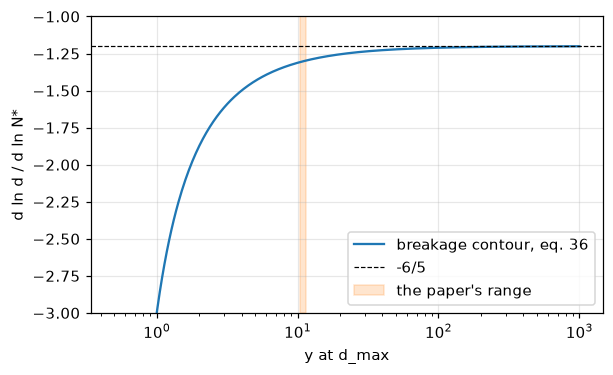

In [9]:
say("With $S$ from R3, the 15 conditions of Figs. 3 and 4 have $y$ = <<a:.2f>> to <<b:.2f>> "
    "at $d_{max}$ (root of $g\\theta = 1$), far from the limit $y\\to\\infty$: the local exponent "
    "$-3(1+2y)/(5y-2)$ runs from <<c:.4f>> to <<d:.4f>>. At 310 rpm, $\\phi$ = 0.10: $y$ = <<e:.3f>>, "
    "exponent <<f:.4f>>, and a finite difference of the root agrees to <<g:.0e>>. The regression "
    "slopes of $\\ln d_{max}$ over the five speeds are <<s1:.4f>>, <<s2:.4f>>, <<s3:.4f>> for "
    "$\\phi$ = 0.05, 0.10, 0.15.",
    a=M["r2_y_min"], b=M["r2_y_max"], c=M["r2_m_min"], d=M["r2_m_max"], e=M["r2_y_T"],
    f=M["r2_m_T"], g=max(M["r2_fd_gap"], 1e-9), s1=M["r2_slope_0.05"], s2=M["r2_slope_0.10"], s3=M["r2_slope_0.15"])
yy = np.geomspace(0.5, 1e3, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(yy[yy > 0.45], contour_exponent(yy[yy > 0.45]), label="breakage contour, eq. 36")
ax.axhline(-1.2, color="k", ls="--", lw=0.8, label="-6/5")
ax.axvspan(M["r2_y_min"], M["r2_y_max"], color="C1", alpha=0.2, label="the paper's range")
ax.set(xlabel="y at d_max", ylabel="d ln d / d ln N*", ylim=(-3, -1))
ax.legend()
plt.show()

### R4: the printed model curves against the reconstruction

Fig. 3: the reconstruction ($S$ from R3, nothing else fitted, $q$ = 8 and 16 extrapolated) lies within the ±0.0012 mm reading error of the printed model lines at 1 of 15 conditions; the largest deviation is 0.0241 mm. Fig. 4 (lines read from 197 to 296 rpm, compared at 220, 250 and 280 rpm): 1 of 9 within ±0.7 %, mean ratio model (s$^{-1}$) to line 1.025, largest deviation 0.058.

Fig. 2: the model volume density ($q$ = 32) peaks at 0.251 mm with 8.50 mm$^{-1}$ and holds 1.46e-03 of its volume above 0.4 mm; the printed theory curve peaks at 0.233 mm with 8.87 mm$^{-1}$, and its reads hold 0.054 between 0.4 and 0.495 mm alone, a lower bound for its tail. Same $d_{32}$ by construction, a different width; the page does not name a cause.

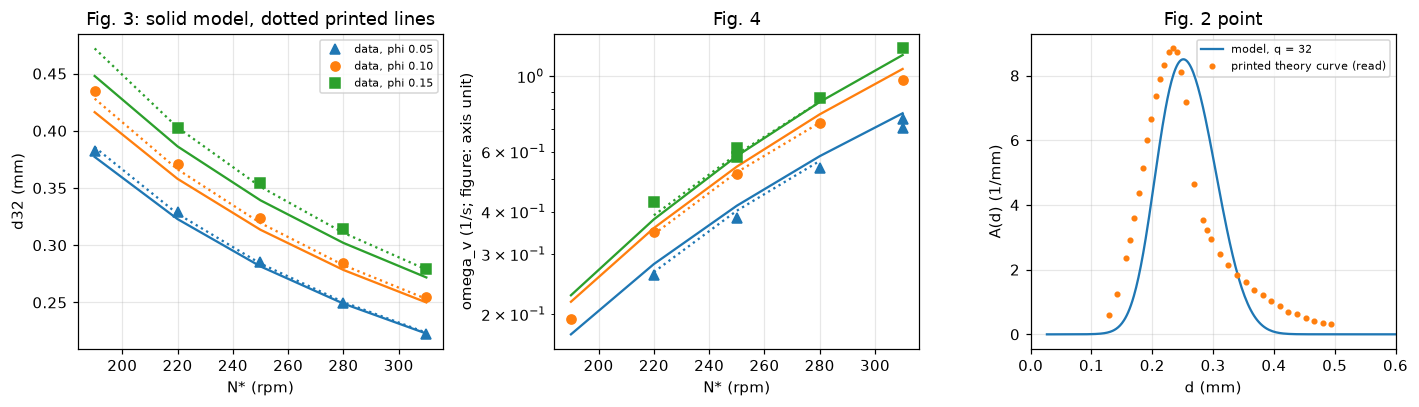

In [10]:
say("Fig. 3: the reconstruction ($S$ from R3, nothing else fitted, $q$ = 8 and 16 "
    "extrapolated) lies within the ±0.0012 mm reading error of the printed model lines at "
    "<<n:d>> of <<n3:d>> conditions; the largest deviation is <<d:.4f>> mm. Fig. 4 (lines read from "
    "197 to 296 rpm, compared at 220, 250 and 280 rpm): <<n4:d>> of <<n49:d>> within ±0.7 %, mean "
    "ratio model (s$^{-1}$) to line <<r4:.3f>>, largest deviation <<d4:.3f>>.",
    n=M["r4_fig3_n_inside"], n3=M["r4_fig3_n_points"], n49=M["r4_fig4_n_points"],
    d=M["r4_fig3_max_dev_mm"], n4=M["r4_fig4_n_inside"],
    r4=M["r4_fig4_mean_ratio"], d4=M["r4_fig4_max_rel_dev"])
say("Fig. 2: the model volume density ($q$ = 32) peaks at <<dm:.3f>> mm with <<am:.2f>> "
    "mm$^{-1}$ and holds <<fm:.2e>> of its volume above 0.4 mm; the printed theory curve peaks "
    "at <<dr:.3f>> mm with <<ar:.2f>> mm$^{-1}$, and its reads hold <<fr:.3f>> between 0.4 and 0.495 mm "
    "alone, a lower bound for its tail. Same $d_{32}$ by construction, a different width; the page does not name "
    "a cause.",
    dm=M["r4_fig2_peak_d_model"], am=M["r4_fig2_peak_A_model"], fm=M["r4_fig2_frac_above_04_model"],
    dr=M["r4_fig2_peak_d_read"], ar=M["r4_fig2_peak_A_read"], fr=M["r4_fig2_frac_04_0495_read"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
res = M["_res"]
for phi, mk, c in zip(PHIS, ("^", "o", "s"), ("C0", "C1", "C2")):
    d = FIG3[(FIG3.phi == f"{phi:.2f}") & (FIG3.kind == "symbol")]
    ax[0].plot(d.N_nominal_rpm, d.d32_mm, mk, color=c, label=f"data, phi {phi:.2f}")
    ax[0].plot(SPEEDS, line_at(FIG3, f"{phi:.2f}", "d32_mm", SPEEDS), ":", color=c)
    ax[0].plot(SPEEDS, res[phi][:, 0] * 10, "-", color=c)
    ax[1].semilogy(SPEEDS, res[phi][:, 1], "-", color=c)
    ax[1].semilogy(SPEEDS[1:4], line_at(FIG4, f"{phi:.2f}", "omega_axis_per_min", SPEEDS[1:4]), ":", color=c)
    d4 = FIG4[(FIG4.phi == f"{phi:.2f}") & (FIG4.kind == "symbol")]
    ax[1].semilogy(d4.N_nominal_rpm, d4.omega_axis_per_min, mk, color=c)
ax[0].set(xlabel="N* (rpm)", ylabel="d32 (mm)", title="Fig. 3: solid model, dotted printed lines")
ax[1].set(xlabel="N* (rpm)", ylabel="omega_v (1/s; figure: axis unit)", title="Fig. 4")
ax[0].legend(fontsize=7)
ax[2].plot(*M["_fig2"], label="model, q = 32")
ax[2].plot(FIG2.d_mm, FIG2.A_per_mm, ".", label="printed theory curve (read)")
ax[2].set(xlim=(0, 0.6), xlabel="d (mm)", ylabel="A(d) (1/mm)", title="Fig. 2 point")
ax[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

### R5: the exponent of d32 in N* over 190 to 310 rpm

In [11]:
tab = pd.DataFrame({
    "phi": PHIS,
    "E15 at d_max": [M[f"r2_slope_{f:.2f}"] for f in PHIS],
    "breakage-only PBE": [M[f"r5_m_brk_{f:.2f}"] for f in PHIS],
    "full PBE": [M[f"r5_m_full_{f:.2f}"] for f in PHIS],
    "breakage-only less -6/5": [M[f"r5_shift_res_{f:.2f}"] for f in PHIS],
    "full less breakage-only": [M[f"r5_shift_coal_{f:.2f}"] for f in PHIS],
    "Fig. 3 lines": [M[f"r5_line_m_{f:.2f}"] for f in PHIS],
    "Fig. 3 data": [M[f"r5_data_m_{f:.2f}"] for f in PHIS],
    "s.e. regression": [M[f"_r5_se_res_{f:.2f}"] for f in PHIS],
    "s.e. reading": [M[f"_r5_se_read_{f:.2f}"] for f in PHIS],
    "data s.e. (larger)": [M[f"r5_data_se_{f:.2f}"] for f in PHIS],
    "t against -6/5": [M[f"r5_data_t_{f:.2f}"] for f in PHIS]})
display(tab.round(4))
_rd = [f for f in PHIS if M[f"_r5_se_read_{f:.2f}"] > M[f"_r5_se_res_{f:.2f}"]]
DOM = (f"the reading term is the larger at {len(_rd)} of {len(PHIS)} holdups"
       + (" ($\\phi$ = " + ", ".join(f"{f:.2f}" for f in _rd) + ")" if _rd else "")
       + " and the regression term at the others")
say("The full model's slope is <<a:.3f>> to <<b:.3f>> over the three holdups (grid error of "
    "a slope at most <<g:.0e>>), its local exponent at 190 and 310 rpm <<la:.3f>> to <<lb:.3f>>; "
    "breakage alone gives <<c:.3f>> to <<d:.3f>>. At the finite $y$ that $g\\theta$ = 1 sets, the "
    "prefactor of eq. 14 steepens the exponent past $-6/5$; coalescence flattens it by "
    "<<k1:.3f>> to <<k2:.3f>>. The standard error of each data slope is the larger of the "
    "regression error and the error that the figure-reading uncertainty of ±<<rd:.4f>> mm "
    "carries into the slope; <<dom>>. The data slopes exclude $-6/5$ at <<nx:d>> of <<nh:d>> "
    "holdups ($|t|$ above the two-sided 95 % point of Student's t, <<t1:.2f>> to <<t2:.2f>> at "
    "their degrees of freedom); pooled with a common slope and one intercept per holdup (dof "
    "<<dof:d>>) the slope is <<pm:.4f>> ± <<pse:.4f>> (<<pdom>>), t = <<pt:.1f>> against $-1.2$. "
    "In Weber numbers the "
    "pooled exponent is <<we:.3f>> against $-0.6$. The local exponent of the full model equals "
    "$-6/5$ at <<nr:d>> speeds between 100 and 600 rpm ($\\phi$ = 0.10).",
    a=min(M[f"r5_m_full_{f:.2f}"] for f in PHIS), b=max(M[f"r5_m_full_{f:.2f}"] for f in PHIS),
    g=M["r5_slope_grid_err"], la=M["r5_mloc_min"], lb=M["r5_mloc_max"],
    c=min(M[f"r5_m_brk_{f:.2f}"] for f in PHIS), d=max(M[f"r5_m_brk_{f:.2f}"] for f in PHIS),
    rd=READ3, nh=len(PHIS), t1=min(M["_r5_tcrit"]), t2=max(M["_r5_tcrit"]),
    dom=DOM,
    pdom=("reading term" if M["_r5_pooled_se_read"] > M["_r5_pooled_se_res"] else "regression term") + " larger",
    k1=min(M[f"r5_shift_coal_{f:.2f}"] for f in PHIS), k2=max(M[f"r5_shift_coal_{f:.2f}"] for f in PHIS),
    nx=M["r5_n_data_excl"], dof=M["r5_pooled_dof"], pm=M["r5_pooled_m"], pse=M["r5_pooled_se"],
    pt=M["r5_pooled_t"], we=M["r5_pooled_m"] / 2, nr=M["r5_n_roots_m_65"])
say("Holdup at 310 rpm, $d_{32}(0.15)/d_{32}(0.05)$: asymptote of breakage alone <<a:.4f>>, "
    "$d_{max}$ <<b:.4f>>, breakage-only balance <<c:.4f>>, full model <<d:.4f>>, printed lines "
    "<<e:.4f>>, data <<f:.4f>>.",
    a=M["r2_holdup_asymptote"], b=M["r2_holdup_dmax"], c=M["r5_holdup_brk"], d=M["r5_holdup_full"],
    e=M["r5_holdup_line"], f=M["r5_holdup_data"])

,phi,E15 at d_max,breakage-only PBE,full PBE,breakage-only less -6/5,full less breakage-only,Fig. 3 lines,Fig. 3 data,s.e. regression,s.e. reading,data s.e. (larger),t against -6/5
0,0.05,-1.3011,-1.3094,-1.0754,-0.1094,0.2340,-1.1143,-1.1142,0.0194,0.0111,0.0194,4.4240
1,0.10,-1.3019,-1.3105,-1.0415,-0.1105,0.2690,-1.0738,-1.0919,0.0070,0.0097,0.0097,11.1415
2,0.15,-1.3027,-1.3115,-1.0199,-0.1115,0.2916,-1.0757,-1.0587,0.0237,0.0143,0.0237,5.9569


The full model's slope is -1.075 to -1.020 over the three holdups (grid error of a slope at most 3e-06), its local exponent at 190 and 310 rpm -1.096 to -1.004; breakage alone gives -1.311 to -1.309. At the finite $y$ that $g\theta$ = 1 sets, the prefactor of eq. 14 steepens the exponent past $-6/5$; coalescence flattens it by 0.234 to 0.292. The standard error of each data slope is the larger of the regression error and the error that the figure-reading uncertainty of ±0.0012 mm carries into the slope; the reading term is the larger at 1 of 3 holdups ($\phi$ = 0.10) and the regression term at the others. The data slopes exclude $-6/5$ at 3 of 3 holdups ($|t|$ above the two-sided 95 % point of Student's t, 3.18 to 4.30 at their degrees of freedom); pooled with a common slope and one intercept per holdup (dof 10) the slope is -1.0951 ± 0.0106 (regression term larger), t = 9.9 against $-1.2$. In Weber numbers the pooled exponent is -0.548 against $-0.6$. The local exponent of the full model equals $-6/5$ at 0 speeds between 100 and 600 rpm ($\phi$ = 0.10).

Holdup at 310 rpm, $d_{32}(0.15)/d_{32}(0.05)$: asymptote of breakage alone 1.1153, $d_{max}$ 1.1253, breakage-only balance 1.1261, full model 1.2202, printed lines 1.2471, data 1.2589.

## Validation

None of these checks uses the data.

In [12]:
say("**V1 conservation.** Volume per breakage column is exact to <<a:.0e>>, and the volume "
    "balance $\\sum x_k y_k = \\phi V_T$ holds to <<b:.0e>>. The hat below the smallest pivot "
    "loses <<c:.2e>> daughters per daughter formed (<<d:.4f>> per fed drop); halving $x_1$ or "
    "taking it tenfold smaller moves $d_{32}$ and $\\omega_n$ by at most <<e:.1e>>.",
    a=max(M["v1_breakage_column_volume"], 1e-16), b=max(M["v1_volume_balance"], 1e-16),
    c=M["v1_deficit_per_daughter"], d=M["v1_deficit_per_fed_drop"], e=M["v1_x1_max_change"])
say("**V2 limits.** Without breakage and coalescence the state is the feed times $\\theta$ to "
    "<<a:.0e>>. Newton on the breakage-only balance from the feed meets the back substitution to "
    "<<b:.0e>>. $X$ a million times larger ($\\lambda \\to 0$) meets breakage alone to <<c:.0e>>, "
    "and $C_3$ times 1e-10 to <<d:.0e>>. A constant kernel without breakage gives <<e:.2e>> "
    "relative to E20, with <<f:.2e>> of the pair rate excluded by the last pivot and the number "
    "balance closed to <<g:.0e>>.",
    a=max(M["v2_residence_identity"], 1e-16), b=max(M["v2_brk_newton_gap"], 1e-16), c=M["v2_xlarge_gap"],
    d=M["v2_c3_continuity"], e=M["v2_const_kernel_gap"], f=M["v2_const_kernel_excluded"],
    g=max(M["v2_const_kernel_number_balance"], 1e-16))
say("**V3 refinement** ($q$ = 4 to 64 at the Fig. 2 point): orders of $d_{32}$ <<a:.3f>> to "
    "<<b:.3f>>, of $\\omega_v$ <<c:.3f>> to <<d:.3f>>, of $\\omega_n$ <<e:.3f>> to <<f:.3f>>, of the "
    "calibrated $S$ <<g:.3f>> to <<h:.3f>> (theory 2); the finest difference of $d_{32}$ is "
    "<<k:.1e>> times its round-off companion (the finest level re-solved with splu). "
    "Extrapolated: $d_{32}$ = <<l:.8f>> cm, $\\omega_v$ = <<m:.6f>> s$^{-1}$, $S$ = <<n:.5f>>.",
    a=M["v3_d32_order_min"], b=M["v3_d32_order_max"], c=M["v3_omega_v_order_min"], d=M["v3_omega_v_order_max"],
    e=M["v3_omega_n_order_min"], f=M["v3_omega_n_order_max"], g=M["v3_S_order_min"], h=M["v3_S_order_max"],
    k=M["v3_finest_over_roundoff"], l=M["v3_d32_ext"], m=M["v3_omega_v_ext"], n=M["v3_S_ext"])
say("**V4 second routes.** A BDF time march to 60 residence times meets the Newton steady state "
    "in $d_{32}$ to <<a:.0e>> at <<n:d>> conditions (the Fig. 2 point and the 15 of R4). The "
    "paper's marching iteration (coalescence lagged by one sweep) <<mc>>; after it stops, "
    "$d_{32}$ is <<g:.3f>> off. With the paper's own stop rule (p. 1293: a relative change of "
    "<<inc:g>> per increment, over the pivots holding more than <<fl:g>> of the largest entry) it "
    "stops after <<sw:d>> sweeps with $d_{32}$ <<sg:.3f>> (relative) below the steady state.",
    a=max(M["v4_bdf_max_gap"], 1e-12), n=M["v4_bdf_n_cases"], inc=C0.march_inc, fl=MARCH_FLOOR,
    sw=M["v4_march_stop_sweeps"], sg=M["v4_march_stop_gap"],
    mc=(f"converges in {M['v4_march_sweeps']} sweeps" if M["v4_march_sweeps"] > 0
        else "does not converge in 500 sweeps"), g=M["v4_march_gap"])
say("**V5 check values.** <<n:d>> values from a second route agree, each inside its own "
    "tolerance (1e-11 to 1e-5).", n=len(DEV))

**V1 conservation.** Volume per breakage column is exact to 2e-16, and the volume balance $\sum x_k y_k = \phi V_T$ holds to 4e-14. The hat below the smallest pivot loses 1.19e-05 daughters per daughter formed (0.5587 per fed drop); halving $x_1$ or taking it tenfold smaller moves $d_{32}$ and $\omega_n$ by at most 1.0e-05.

**V2 limits.** Without breakage and coalescence the state is the feed times $\theta$ to 2e-16. Newton on the breakage-only balance from the feed meets the back substitution to 2e-16. $X$ a million times larger ($\lambda \to 0$) meets breakage alone to 2e-16, and $C_3$ times 1e-10 to 1e-08. A constant kernel without breakage gives 1.03e-02 relative to E20, with 2.10e-02 of the pair rate excluded by the last pivot and the number balance closed to 2e-16.

**V3 refinement** ($q$ = 4 to 64 at the Fig. 2 point): orders of $d_{32}$ 1.990 to 2.008, of $\omega_v$ 1.994 to 1.999, of $\omega_n$ 1.993 to 1.995, of the calibrated $S$ 1.990 to 1.991 (theory 2); the finest difference of $d_{32}$ is 1.6e+09 times its round-off companion (the finest level re-solved with splu). Extrapolated: $d_{32}$ = 0.02499919 cm, $\omega_v$ = 1.049112 s$^{-1}$, $S$ = 48.68853.

**V4 second routes.** A BDF time march to 60 residence times meets the Newton steady state in $d_{32}$ to 1e-12 at 16 conditions (the Fig. 2 point and the 15 of R4). The paper's marching iteration (coalescence lagged by one sweep) does not converge in 500 sweeps; after it stops, $d_{32}$ is 0.076 off. With the paper's own stop rule (p. 1293: a relative change of 0.001 per increment, over the pivots holding more than 1e-06 of the largest entry) it stops after 357 sweeps with $d_{32}$ 0.074 (relative) below the steady state.

**V5 check values.** 60 values from a second route agree, each inside its own tolerance (1e-11 to 1e-5).

### The claims

In [13]:
RTOL = 1e-6
STRUCTURAL = {"v2_residence_identity": "no breakage, no coalescence: y = feed theta by construction",
              "v4_bdf_n_cases": "the Fig. 2 point and the 15 conditions of R4",
              "r4_fig3_n_points": "five speeds times three holdups",
              "r4_fig4_n_points": "three speeds inside the line reads times three holdups",
              "r5_pooled_dof": "14 symbols less a common slope and three intercepts",
              "v2_const_kernel_number_balance": "number exact per coalescence event on the fixed pivot (weights sum to one)"}
BOUNDS = {"v1_breakage_column_volume": (None, 1e-13, "identity", "x B = x per breakage column (fixed pivot)"),
          "v1_volume_balance": (None, 1e-12, "identity", "sum x y = phi V_T at the steady state"),
          "v2_residence_identity": (None, 1e-14, "identity", STRUCTURAL["v2_residence_identity"]),
          "v2_brk_newton_gap": (None, 1e-10, "tolerance", "newton tol 1e-12 against the back substitution"),
          "v2_xlarge_gap": (None, 1e-6, "theory", "lambda -> 0: breakage alone"),
          "v2_c3_continuity": (None, 1e-6, "theory", "C3 -> 0: breakage alone"),
          "v2_const_kernel_number_balance": (None, 1e-12, "identity", "N/theta + events = n0 on the fixed pivot"),
          "v1_x1_max_change": (None, 1e-3, "chosen", "domain immaterial (plan stop rule)"),
          "r3_feed_max_change": (None, 1e-3, "chosen", "feed immaterial (plan stop rule)"),
          "r3_domain_max_change": (None, 1e-3, "chosen", "domain immaterial (plan stop rule)"),
          "r2_fd_gap": (None, 1e-6, "tolerance", "central difference h 1e-4 of the find_roots root"),
          "v4_bdf_max_gap": (None, 1e-6, "tolerance", "BDF rtol 1e-10 to 60 theta against newton"),
          "v3_finest_over_roundoff": (1e3, None, "chosen", "claims-design: finest difference 1e3 times round-off"),
          "r5_slope_grid_err": (None, 2e-5, "tolerance", "q and 2q extrapolated against 2q")}
for k in ("d32", "omega_v", "omega_n", "S"):
    for e in ("min", "max"):
        BOUNDS[f"v3_{k}_order_{e}"] = (1.7, 2.3, "theory", "fixed pivot on smooth densities: 2")
COUNTS = {"r1_fig1_n_follow": 0.05, "r1_C4_est_n_reproduced": 0.01, "r4_fig3_n_inside": 0.05,
          "r4_fig4_n_inside": 0.05, "r5_n_data_excl": 0.05}
EXACT = {"r3_n_roots", "r3_pv_n_roots", "r5_pooled_dof", "v4_march_sweeps", "v4_march_stop_sweeps",
         "r5_n_roots_m_65", "v4_bdf_n_cases"}
MARGINED = {"r1_C4_bracket_holds": 0.05, "r3_printed_in_band": 0.001}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in MARGINED:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=MARGINED[name])
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=RTOL)


register(M)

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through `Cfg` (a reading, a law, a printed entry, a data read or a solver
setting) and reruns the parts of the study the defect reaches; the claims it fails are
counted. A claim a row's parts do not compute is not counted for that row. A row under
which the study raises is listed as a crash, not as a catch. The control fails nothing.

In [14]:
def printed_row(item, new, parts=ALL):
    """A break row that mistypes one printed entry."""
    pn = PN.copy()
    i = pn.index[pn["item"] == item][0]
    old = pn.at[i, "printed"]
    pn.at[i, "printed"] = new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn), parts


def data_row(label, fig, mask, col, factor, parts=("closed", "cal", "sweep")):
    """A break row that scales a subset of one figure's reads."""
    df = getattr(C0, fig).copy()
    df.loc[mask(df), col] = df.loc[mask(df), col].astype(float) * factor
    return label, replace(C0, **{fig: df}), parts


NOLAD = tuple(p_ for p_ in ALL if p_ not in ("ladder", "local"))
DEFECTS = [
    ("counts per cm3 (C3 / V_T)", replace(C0, over=(("per_volume", True),)), NOLAD),
    ("omega_v read in 1/min", replace(C0, unit=60.0), ("closed", "cal", "sweep")),
    ("constant of eq. 26 unity in the C4 estimate", replace(C0, est=(("contact", "unity"),)), ("closed",)),
    ("Rotta factor in the C3 estimate", replace(C0, est=(("rotta_in_c3", True),)), ("closed",)),
    ("c2 = 1/2 in eq. 9", replace(C0, est=(("c2", "1/2"),)), ("closed",)),
    ("eps = epsbar in the impeller region", replace(C0, est=(("cutter", 1.0),)), ("closed",)),
    ("eq. 25 exponent 2 for 4", replace(C0, over=(("shape_power", 2.0),)), NOLAD),
    ("beta with the printed 2.4", replace(C0, over=(("beta", "printed"),)), ("closed", "cal", "valid")),
    ("nearest-pivot coalescence products", replace(C0, over=(("assign", "nearest"),)), ("closed", "cal", "valid", "ladder")),
    ("no (1 + phi) damping", replace(C0, over=(("damp", 0.0),)), NOLAD),
    ("theta = 10 s", replace(C0, over=(("theta", 10.0),)), NOLAD),
    ("C3 = 0", replace(C0, over=(("C3", 0.0),)), ALL),
    ("production grid q = 4", replace(C0, q=4), ("closed", "cal", "sweep", "valid")),
    ("feed mean diameter 0.1 mm", replace(C0, d0=0.01), ("closed", "cal", "valid")),
    ("smallest pivot tenfold larger", replace(C0, x1=1e-7), ("closed", "cal", "valid")),
    ("6 % efficiency read as 8 %", replace(C0, lam6=0.08), ("closed", "cal", "r2")),
    ("V2 newton route with the feed 1e-6 high", replace(C0, v2_feedfac=1 + 1e-6), ("closed", "cal", "valid")),
    ("V2 lambda -> 0 at X x 100 only", replace(C0, v2_xfac=100.0), ("closed", "cal", "valid")),
    ("V2 C3 -> 0 at C3 x 0.01 only", replace(C0, v2_c3fac=0.01), ("closed", "cal", "valid")),
    ("BDF march to 0.01 residence times", replace(C0, bdf_span=0.01), ("closed", "cal", "valid")),
    ("marching stop rule 0.01 per increment", replace(C0, march_inc=1e-2), ("closed", "cal", "valid")),
    ("R2 finite-difference step 0.3 in ln N*", replace(C0, fd_h=0.3), ("closed", "cal", "r2")),
    ("grid ends at 0.34 mm (11 doublings)", replace(C0, octaves=11), ("closed", "cal")),
    ("production grid q = 2", replace(C0, q=2), ("closed", "cal", "sweep")),
    ("V3 companion solved with C3 1e-6 relative high", replace(C0, comp_c3=1 + 1e-6), ("closed", "cal", "ladder")),
    ("V3 ladder with C1 off by 50/q^3 %", replace(C0, c1_qdefect=0.5), ("closed", "cal", "ladder")),
    printed_row("C4", "1.38e9", ("closed", "cal", "r2", "sweep")),
    printed_row("C2", "0.09", ("closed", "cal", "r2")),
    printed_row("fig2_d32_calc_mm", "0.260", ("closed", "cal", "r2", "fig2")),
    printed_row("fig2_omega_v_calc", "1.062", ("closed", "cal")),
    printed_row("fig2_d32_calc_mm", "2.50", ("closed", "cal")),
    printed_row("fig1_CII", "0.116", ("closed",)),
    printed_row("C4_est_h500", "0.69e10", ("closed",)),
    printed_row("C3_est", "1.6e-4", ("closed",)),
    printed_row("C2_est_coef", "0.16", ("closed",)),
    printed_row("C1_est_coef", "2.75", ("closed",)),
    printed_row("v6_a_cm3", "2.88e-5", ("closed",)),
    data_row("Fig. 3 symbols at 310 rpm 3 % high", "fig3",
             lambda d: (d.kind == "symbol") & (d.N_nominal_rpm == 310), "d32_mm", 1.03),
    data_row("Fig. 3 phi 0.15 symbols 1 % high", "fig3",
             lambda d: (d.kind == "symbol") & (d.phi == "0.15"), "d32_mm", 1.01),
    data_row("Fig. 3 line reads above 280 rpm 2 % high", "fig3",
             lambda d: (d.kind == "line") & (d.N_read_rpm > 280), "d32_mm", 1.02),
    data_row("Fig. 4 line reads 3 % high", "fig4", lambda d: d.kind == "line", "omega_axis_per_min", 1.03),
    data_row("Fig. 3 phi 0.15 line reads 2 % high", "fig3",
             lambda d: (d.kind == "line") & (d.phi == "0.15"), "d32_mm", 1.02),
    data_row("Fig. 3 phi 0.05 symbol at 190 rpm 8 % high", "fig3",
             lambda d: (d.kind == "symbol") & (d.phi == "0.05") & (d.N_nominal_rpm == 190), "d32_mm", 1.08),
    data_row("Fig. 2 curve reads 3 % to larger d", "fig2", lambda d: d.d_mm > 0, "d_mm", 1.03, ("closed", "cal", "fig2")),
    data_row("Fig. 2 curve reads 5 % high", "fig2", lambda d: d.d_mm > 0, "A_per_mm", 1.05, ("closed", "cal", "fig2")),
]
CONTROLS = [("control: clean rerun of the cheap parts", C0, ("closed", "cal", "r2", "fig2"))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], set()
for row, c_, parts in CONTROLS + DEFECTS:
    try:
        with np.errstate(divide="ignore", invalid="ignore"):   # a broken row may divide by zero
            Mb = study(c_, parts)
    except (ValueError, RuntimeError, np.linalg.LinAlgError, IndexError) as e:
        print(f"{row}: {type(e).__name__}: {e}")
        Mb = {}
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        # only finite values a row's parts produce are recorded; a crash is listed apart
        if x_ is None or (isinstance(x_, (float, np.floating)) and not np.isfinite(x_)):
            continue
        BREAK.append((row, name, claims.breaks(row, name, x_)))
    if not any(name in Mb for name in claims.metrics):
        CRASH.add(row)

In [15]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<52} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:52]:<52} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_ and r_ not in CRASH}
print(f"rows that only crash: {', '.join(sorted(CRASH)) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                      claims failed
control: clean rerun of the cheap parts                          0
counts per cm3 (C3 / V_T)                                       52
omega_v read in 1/min                                            9
constant of eq. 26 unity in the C4 estimate                      3
Rotta factor in the C3 estimate                                  3
c2 = 1/2 in eq. 9                                                2
eps = epsbar in the impeller region                              4
eq. 25 exponent 2 for 4                                         54
beta with the printed 2.4                                       22
nearest-pivot coalescence products                              30
no (1 + phi) damping                                            59
theta = 10 s                                                    55
C3 = 0                                                          61
production grid q = 4                                         

## What pymrm adds

Nothing to the model: the kernels and the balance are the paper's, and the population
balance has no space coordinate, so no finite-volume operator is used. pymrm contributes
the solve and the checks: `pymrm.newton` solves the dense discretised steady balance with
its analytic Jacobian, bounds at zero and scaling, from the exact breakage-only state, at
every condition of the page; `pymrm.checks.find_roots` gives every calibration and
threshold as a root with its count on the whole physical range ($S$, $d_{max}$, the speed
where the local exponent would equal $-6/5$, the peak of the volume density);
`pymrm.checks.observed_orders` measures the grid orders and the extrapolated values. The
independent routes are plain numpy and scipy (a BDF time march and the check values).
What the page adds to the paper is a set of checks it does not print: the counting
convention and the frequency unit decided by the paper's own printed model numbers, the
exponent shift owed to coalescence, and the data slopes with their standard errors, which
carry the figure-reading error.

## Reuse

- The kernels are functions of $S$, $X$, $N^{\ast}$, $\phi$ and a `Params` object; another
  system changes $S$ and $X$ (and the vessel's $D$, $V_T$, $\theta$). $C_3$ is per vessel:
  for another vessel volume divide by its $V_T$ in the same way, which is a reading, not a
  tested scale-up rule.
- `SteadyPBE` takes any $q$; the fixed pivot converges at second order here, so two grids
  and one Richardson step give values to about the fifth digit.
- Related pages: `J2.1` (the general population balance), `J2.2` (MSMPR crystalliser),
  `J2.4` (the fixed pivot), `J2.5` (QMOM), `J2.6` (Smoluchowski aggregation kinetics),
  `J2.8` and `J2.9` (other kernels).

In [16]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for J2.7:
  r1_fig1_CI_half_units          = 23.652           value  rtol 1e-06
  r1_fig1_CII_half_units         = 0.4              value  rtol 1e-06
  r1_fig1_CIII_half_units        = 22.957           value  rtol 1e-06
  r1_fig1_CIV_half_units         = 0.065094         value  rtol 1e-06
  r1_fig1_n_follow               = 2                exact  exact, margin 0.6
  r1_C4_est_h1000                = 1.4837e+09       value  rtol 1e-06
  r1_C4_est_h500                 = 5.9349e+09       value  rtol 1e-06
  r1_C4_est_n_reproduced         = 2                exact  exact, margin 0.257
  r1_C4_bracket_holds            = True             exact  exact, margin 0.21
  r1_C3_est                      = 0.00014933       value  rtol 1e-06
  r1_C3_est_half_units           = 0.13464          value  rtol 1e-06
  r1_C3_est_over_fitted          = 53.331           value  rtol 1e-06
  r1_C2_est_half_units           = 0.40862          value  rtol 1e-06
  r1_C1_est_half_units           = 0.96704       